<a href="https://colab.research.google.com/github/HemanthGadiraju/telecom_churn/blob/main/Telecom_Churn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

Dataset loaded successfully!
Dataset shape: (7043, 21)


In [ ]:
import os
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score, ConfusionMatrixDisplay
os.makedirs("figs", exist_ok=True)

In [ ]:
print("First five rows:")
display(df.head())

print("Column names:")
print(df.columns.tolist())

print("Dataset information:")
df.info()

print("Missing values in each column:")
print(df.isnull().sum())

First five rows:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


Column names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']
Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecuri

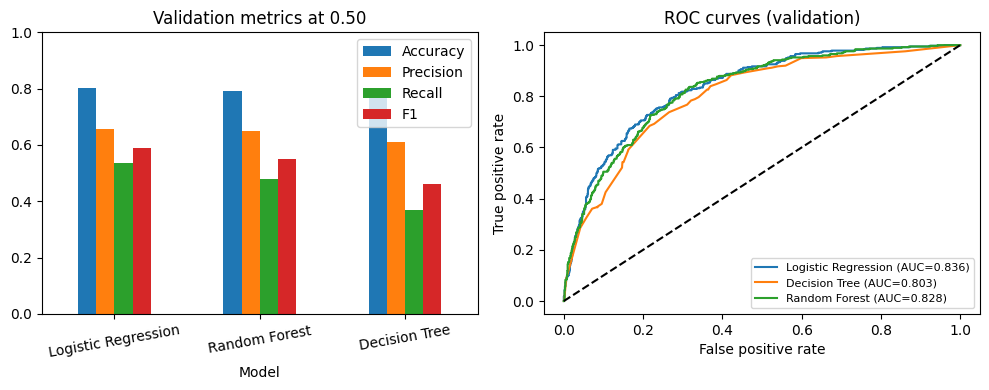

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
results_df.set_index("Model")[["Accuracy", "Precision", "Recall", "F1"]].plot.bar(ax=axes[0], rot=10)
axes[0].set_ylim(0, 1); axes[0].set_title("Validation metrics at 0.50")
for name, model in trained_models.items():
    p = model.predict_proba(X_val)[:, 1]
    fpr, tpr, _ = roc_curve(y_val, p)
    axes[1].plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_val, p):.3f})")
axes[1].plot([0, 1], [0, 1], "k--")
axes[1].set_xlabel("False positive rate"); axes[1].set_ylabel("True positive rate")
axes[1].set_title("ROC curves (validation)"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig("figs/fig07_models.png", dpi=150); plt.show()

Churn counts:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn percentages:
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


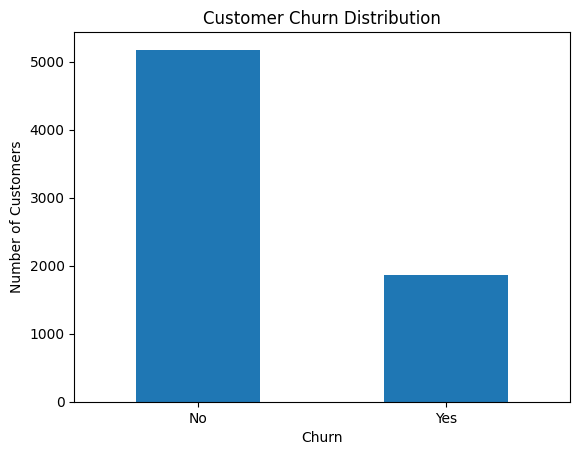

In [ ]:
print("Churn counts:")
print(df["Churn"].value_counts())

print("\nChurn percentages:")
print(df["Churn"].value_counts(normalize=True).mul(100).round(2))

df["Churn"].value_counts().plot(kind="bar")
plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.show()

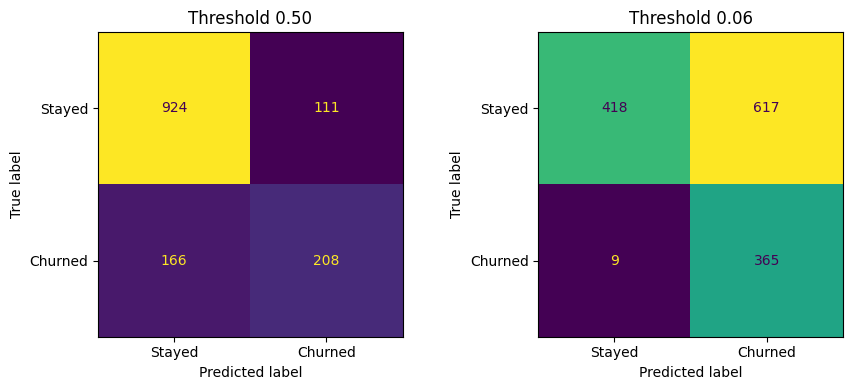

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, t in zip(axes, [0.50, best_threshold]):
    pred = (test_probabilities >= t).astype(int)
    ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["Stayed", "Churned"], ax=ax, colorbar=False)
    ax.set_title(f"Threshold {t:.2f}")
plt.tight_layout(); plt.savefig("figs/fig09_cm.png", dpi=150); plt.show()

In [ ]:
# Make a copy so the original dataset stays unchanged
data = df.copy()

# Remove customerID because it is an identifier, not a general predictive feature
data = data.drop(columns=["customerID"])

# Convert TotalCharges to numeric; blank strings become missing values
data["TotalCharges"] = pd.to_numeric(
    data["TotalCharges"],
    errors="coerce"
)

# In this dataset, blank TotalCharges rows are zero-tenure customers.
# Confirm this assumption before filling these values with zero.
zero_tenure = data["tenure"].eq(0)
data.loc[zero_tenure & data["TotalCharges"].isna(), "TotalCharges"] = 0

# Convert the target: Yes = 1, No = 0
data["Churn"] = data["Churn"].map({"Yes": 1, "No": 0})

print("Missing TotalCharges after zero-tenure handling:",
      data["TotalCharges"].isna().sum())
print("Missing target values:", data["Churn"].isna().sum())
print("Cleaned dataset shape:", data.shape)

Missing TotalCharges after zero-tenure handling: 0
Missing target values: 0
Cleaned dataset shape: (7043, 20)


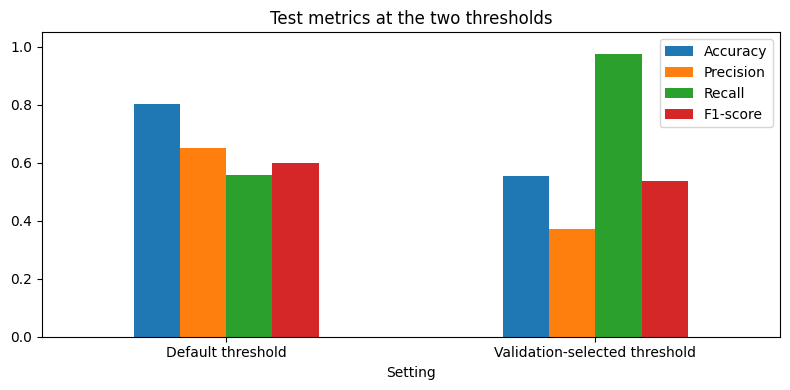

In [ ]:
comparison_df.set_index("Setting")[["Accuracy", "Precision", "Recall", "F1-score"]].plot.bar(rot=0, figsize=(8, 4))
plt.ylim(0, 1.05); plt.title("Test metrics at the two thresholds")
plt.tight_layout(); plt.savefig("figs/fig11_thresh_cmp.png", dpi=150); plt.show()

In [ ]:
X = data.drop(columns=["Churn"])
y = data["Churn"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget examples:")
print(y.head())

Features shape: (7043, 19)
Target shape: (7043,)

Target examples:
0    0
1    0
2    1
3    0
4    1
Name: Churn, dtype: int64


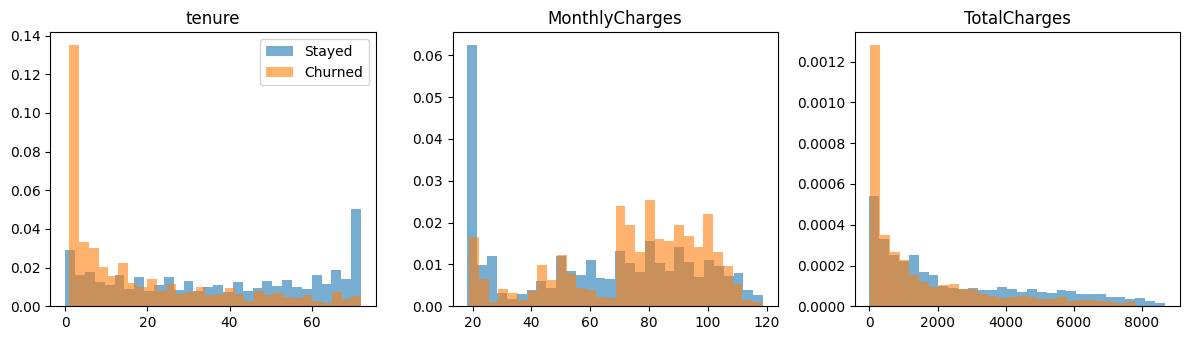

In [ ]:
num = ["tenure", "MonthlyCharges", "TotalCharges"]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, c in zip(axes, num):
    for v, lab in [(0, "Stayed"), (1, "Churned")]:
        ax.hist(data.loc[data["Churn"] == v, c], bins=30, alpha=0.6, density=True, label=lab)
    ax.set_title(c)
axes[0].legend()
plt.tight_layout(); plt.savefig("figs/fig02_numeric_hist.png", dpi=150); plt.show()

In [ ]:
from sklearn.model_selection import train_test_split

# First, reserve 20% for final testing
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# From the remaining 80%, reserve 25% for validation.
# This gives approximately 60% training, 20% validation, 20% testing.
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val,
    y_train_val,
    test_size=0.25,
    random_state=42,
    stratify=y_train_val
)

print("Training rows:", len(X_train))
print("Validation rows:", len(X_val))
print("Testing rows:", len(X_test))

Training rows: 4225
Validation rows: 1409
Testing rows: 1409


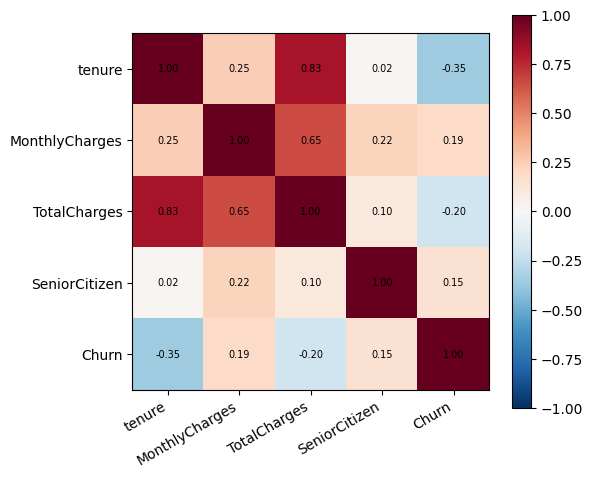

In [ ]:
corr = data[num + ["SeniorCitizen", "Churn"]].corr()
plt.figure(figsize=(6, 5))
plt.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1); plt.colorbar()
plt.xticks(range(len(corr)), corr.columns, rotation=30, ha="right")
plt.yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        plt.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
plt.tight_layout(); plt.savefig("figs/fig05_corr.png", dpi=150); plt.show()

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("Numerical features:", numeric_features)
print("Categorical feature count:", len(categorical_features))

Numerical features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical feature count: 15


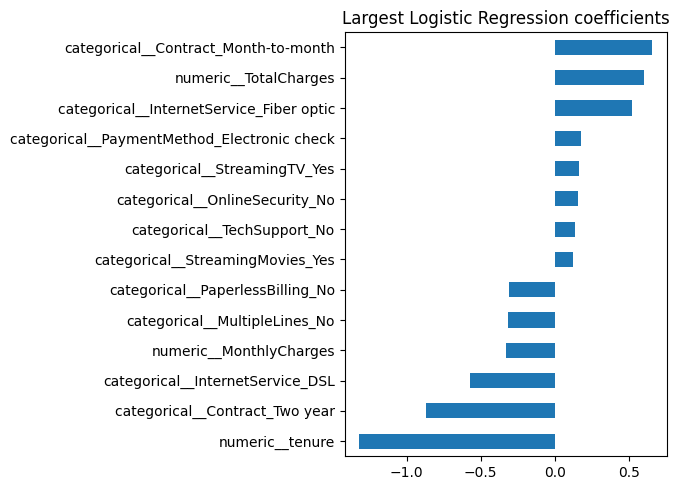

In [ ]:
import pandas as pd
names = best_model.named_steps["preprocessor"].get_feature_names_out()
coef = pd.Series(best_model.named_steps["classifier"].coef_[0], index=names).sort_values()
top = pd.concat([coef.head(6), coef.tail(8)])
top.plot.barh(figsize=(7, 5))
plt.title("Largest Logistic Regression coefficients")
plt.tight_layout(); plt.savefig("figs/fig10_coef.png", dpi=150); plt.show()

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=6,
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        max_depth=12,
        random_state=42,
        n_jobs=-1
    )
}

trained_models = {}

for name, model in models.items():
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

    pipeline.fit(X_train, y_train)
    trained_models[name] = pipeline

    print(name, "trained successfully")

Logistic Regression trained successfully
Decision Tree trained successfully
Random Forest trained successfully


In [ ]:
!zip -r figs.zip figs
from google.colab import files
files.download("figs.zip")

  adding: figs/ (stored 0%)
  adding: figs/fig07_models.png (deflated 11%)
  adding: figs/fig10_coef.png (deflated 18%)
  adding: figs/fig05_corr.png (deflated 11%)
  adding: figs/fig09_cm.png (deflated 19%)
  adding: figs/fig02_numeric_hist.png (deflated 22%)
  adding: figs/fig11_thresh_cmp.png (deflated 22%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

results = []

for name, model in trained_models.items():
    probabilities = model.predict_proba(X_val)[:, 1]
    predictions = (probabilities >= 0.50).astype(int)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, predictions),
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_val, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_val, probabilities)
    })

results_df = pd.DataFrame(results).sort_values(
    "ROC-AUC",
    ascending=False
)

display(results_df.round(3))

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.803,0.658,0.535,0.590,0.836
2,Random Forest,0.793,0.649,0.479,0.551,0.828
1,Decision Tree,0.770,0.611,0.369,0.460,0.803


In [ ]:
from sklearn.metrics import confusion_matrix

# Choose the model with the highest validation ROC-AUC
best_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_name]
print("Selected model:", best_name)

# Predict churn probabilities on validation data
val_probabilities = best_model.predict_proba(X_val)[:, 1]

# Illustrative assumptions (replace with business-approved estimates if available)
cost_offer = 10
cost_missed_churn = 100

threshold_results = []

# Test thresholds from 0.01 to 0.95 in increments of 0.01.
# Threshold selection uses validation data only, not test data.
for threshold in np.arange(0.01, 0.951, 0.01):
    predictions = (val_probabilities >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val, predictions, labels=[0, 1]
    ).ravel()

    # Every customer predicted to churn receives an offer: TP + FP.
    total_offers = tp + fp
    total_cost = (
        total_offers * cost_offer
        + fn * cost_missed_churn
    )

    threshold_results.append({
        "Threshold": round(float(threshold), 2),
        "True Negatives": tn,
        "False Positives": fp,
        "False Negatives": fn,
        "True Positives": tp,
        "Customers Flagged": total_offers,
        "Total Cost": total_cost
    })

threshold_df = pd.DataFrame(threshold_results)
best_row = threshold_df.loc[threshold_df["Total Cost"].idxmin()]
best_threshold = float(best_row["Threshold"])

display(threshold_df.sort_values("Total Cost").head(10))
print("Selected threshold:", best_threshold)
print("Lowest validation cost:", int(best_row["Total Cost"]))
print("Cost assumptions: offer =", cost_offer,
      "| missed churner =", cost_missed_churn)

Selected model: Logistic Regression


,Threshold,True Negatives,False Positives,False Negatives,True Positives,Customers Flagged,Total Cost
5,0.06,409,626,12,362,988,11080
6,0.07,433,602,16,358,960,11200
7,0.08,458,577,21,353,930,11400
4,0.05,377,658,12,362,1020,11400
12,0.13,565,470,33,341,811,11410
11,0.12,543,492,31,343,835,11450
3,0.04,339,696,9,365,1061,11510
13,0.14,575,460,36,338,798,11580
8,0.09,475,560,25,349,909,11590
9,0.10,506,529,29,345,874,11640


Selected threshold: 0.06
Lowest validation cost: 11080
Cost assumptions: offer = 10 | missed churner = 100


In [ ]:
from sklearn.metrics import (
    classification_report, accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score, confusion_matrix
)

# The test set is used only for final evaluation.
test_probabilities = best_model.predict_proba(X_test)[:, 1]
test_predictions = (test_probabilities >= best_threshold).astype(int)

print("Final model:", best_name)
print("Threshold selected using validation data:", best_threshold)

print("\nTEST SET CLASSIFICATION REPORT")
print(classification_report(
    y_test, test_predictions,
    target_names=["Stayed", "Churned"],
    zero_division=0
))

tn, fp, fn, tp = confusion_matrix(
    y_test, test_predictions, labels=[0, 1]
).ravel()

print("TEST SET CONFUSION MATRIX")
print(np.array([[tn, fp], [fn, tp]]))

print("\nTEST SET METRICS")
print("Accuracy:", round(accuracy_score(y_test, test_predictions), 3))
print("Precision:", round(precision_score(y_test, test_predictions, zero_division=0), 3))
print("Recall:", round(recall_score(y_test, test_predictions, zero_division=0), 3))
print("F1-score:", round(f1_score(y_test, test_predictions, zero_division=0), 3))
print("ROC-AUC:", round(roc_auc_score(y_test, test_probabilities), 3))

# Count offer cost for every customer flagged (TP + FP), plus missed churn cost.
total_offers = tp + fp
test_cost = total_offers * cost_offer + fn * cost_missed_churn

print("\nTEST SET BUSINESS COST")
print("Customers flagged / offers:", total_offers)
print("True negatives:", tn)
print("False positives:", fp)
print("False negatives:", fn)
print("True positives:", tp)
print("Total estimated cost:", test_cost)

Final model: Logistic Regression
Threshold selected using validation data: 0.06

TEST SET CLASSIFICATION REPORT
              precision    recall  f1-score   support

      Stayed       0.98      0.40      0.57      1035
     Churned       0.37      0.98      0.54       374

    accuracy                           0.56      1409
   macro avg       0.68      0.69      0.56      1409
weighted avg       0.82      0.56      0.56      1409

TEST SET CONFUSION MATRIX
[[418 617]
 [  9 365]]

TEST SET METRICS
Accuracy: 0.556
Precision: 0.372
Recall: 0.976
F1-score: 0.538
ROC-AUC: 0.843

TEST SET BUSINESS COST
Customers flagged / offers: 982
True negatives: 418
False positives: 617
False negatives: 9
True positives: 365
Total estimated cost: 10720


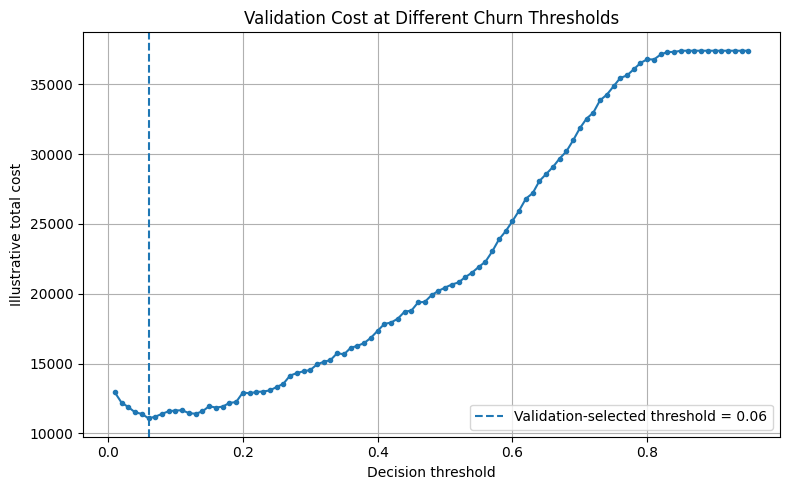

In [ ]:
plt.figure(figsize=(8, 5))
plt.plot(
    threshold_df["Threshold"],
    threshold_df["Total Cost"],
    marker="."
)
plt.axvline(
    best_threshold,
    linestyle="--",
    label=f"Validation-selected threshold = {best_threshold:.2f}"
)
plt.title("Validation Cost at Different Churn Thresholds")
plt.xlabel("Decision threshold")
plt.ylabel("Illustrative total cost")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
import joblib

# Save model and the threshold/cost assumptions together.
joblib.dump({
    "model": best_model,
    "model_name": best_name,
    "threshold": best_threshold,
    "cost_offer": cost_offer,
    "cost_missed_churn": cost_missed_churn
}, "telecom_churn_model.joblib")

results_df.to_csv("model_comparison.csv", index=False)
threshold_df.to_csv("threshold_cost_comparison.csv", index=False)

# Save test metrics and confusion counts for the report.
test_summary = pd.DataFrame([{
    "Model": best_name,
    "Threshold": best_threshold,
    "Accuracy": accuracy_score(y_test, test_predictions),
    "Precision": precision_score(y_test, test_predictions, zero_division=0),
    "Recall": recall_score(y_test, test_predictions, zero_division=0),
    "F1": f1_score(y_test, test_predictions, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, test_probabilities),
    "TN": tn, "FP": fp, "FN": fn, "TP": tp,
    "Customers Flagged": total_offers,
    "Estimated Cost": test_cost
}])
test_summary.to_csv("test_set_evaluation.csv", index=False)

print("Saved model and threshold metadata: telecom_churn_model.joblib")
print("Saved model comparison: model_comparison.csv")
print("Saved threshold comparison: threshold_cost_comparison.csv")
print("Saved test evaluation: test_set_evaluation.csv")

Saved model and threshold metadata: telecom_churn_model.joblib
Saved model comparison: model_comparison.csv
Saved threshold comparison: threshold_cost_comparison.csv
Saved test evaluation: test_set_evaluation.csv


In [ ]:
# The final test-set evaluation is already performed in Step 10.
# Avoid repeatedly evaluating or tuning on the test set.
print("Test evaluation is reported in Step 10.")

Test evaluation is reported in Step 10.


In [ ]:
# Compare the default threshold with the validation-selected threshold.
# This is a final descriptive comparison; do not use it to retune the threshold.

default_predictions = (test_probabilities >= 0.50).astype(int)

def calculate_business_cost(y_true, predictions,
                            offer_cost, missed_churn_cost):
    tn_, fp_, fn_, tp_ = confusion_matrix(
        y_true, predictions, labels=[0, 1]
    ).ravel()
    offers_ = tp_ + fp_
    cost_ = offers_ * offer_cost + fn_ * missed_churn_cost
    return cost_, offers_, tn_, fp_, fn_, tp_

default_cost, default_offers, *_ = calculate_business_cost(
    y_test, default_predictions, cost_offer, cost_missed_churn
)
optimized_cost, optimized_offers, *_ = calculate_business_cost(
    y_test, test_predictions, cost_offer, cost_missed_churn
)

print("Default threshold (0.50) cost:", default_cost)
print("Validation-selected threshold cost:", optimized_cost)
print("Cost difference (default - selected):", default_cost - optimized_cost)
print("Customers flagged at 0.50:", default_offers)
print("Customers flagged at selected threshold:", optimized_offers)

Default threshold (0.50) cost: 19790
Validation-selected threshold cost: 10720
Cost difference (default - selected): 9070
Customers flagged at 0.50: 319
Customers flagged at selected threshold: 982


In [ ]:
comparison = []

for threshold, label in [
    (0.50, "Default threshold"),
    (best_threshold, "Validation-selected threshold")
]:
    predictions = (test_probabilities >= threshold).astype(int)
    comparison.append({
        "Setting": label,
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1-score": f1_score(y_test, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, test_probabilities),
        "Customers flagged": int(predictions.sum())
    })

comparison_df = pd.DataFrame(comparison)
display(comparison_df.round(3))

,Setting,Threshold,Accuracy,Precision,Recall,F1-score,ROC-AUC,Customers flagged
0,Default threshold,0.50,0.803,0.652,0.556,0.600,0.843,319
1,Validation-selected threshold,0.06,0.556,0.372,0.976,0.538,0.843,982
